# 01 — EDA: Format-Specific Features
## How do format features distribute and correlate with performance?

In [1]:
import sys, json, warnings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

df = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'format_dataset.parquet')
with open(PROJECT_ROOT / 'format_features_reference.json', 'r', encoding='utf-8') as f:
    ref = json.load(f)

format_features = [feat['name'] for feat in ref['features']]
feat_types = {feat['name']: feat['type'] for feat in ref['features']}
categorical_feats = [f for f in format_features if feat_types[f] in ('categorical', 'boolean', 'multi-select') and f in df.columns]
numeric_feats = [f for f in format_features if feat_types[f] == 'numeric' and f in df.columns]

print(f'Dataset: {df.shape[0]} posts x {df.shape[1]} columns')
print(f'Format features: {len(format_features)} ({len(categorical_feats)} categorical, {len(numeric_feats)} numeric)')

Dataset: 140 posts x 107 columns
Format features: 15 (6 categorical, 9 numeric)


## Categorical Feature Distributions

In [2]:
n_cat = len(categorical_feats)
fig, axes = plt.subplots(n_cat, 1, figsize=(12, 4 * n_cat))
if n_cat == 1:
    axes = [axes]

for ax, feat in zip(axes, categorical_feats):
    counts = df[feat].value_counts()
    counts.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(feat, fontsize=13, fontweight='bold')
    ax.set_xlabel('Count')
    for i, v in enumerate(counts):
        ax.text(v + 0.5, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

## Numeric Feature Distributions

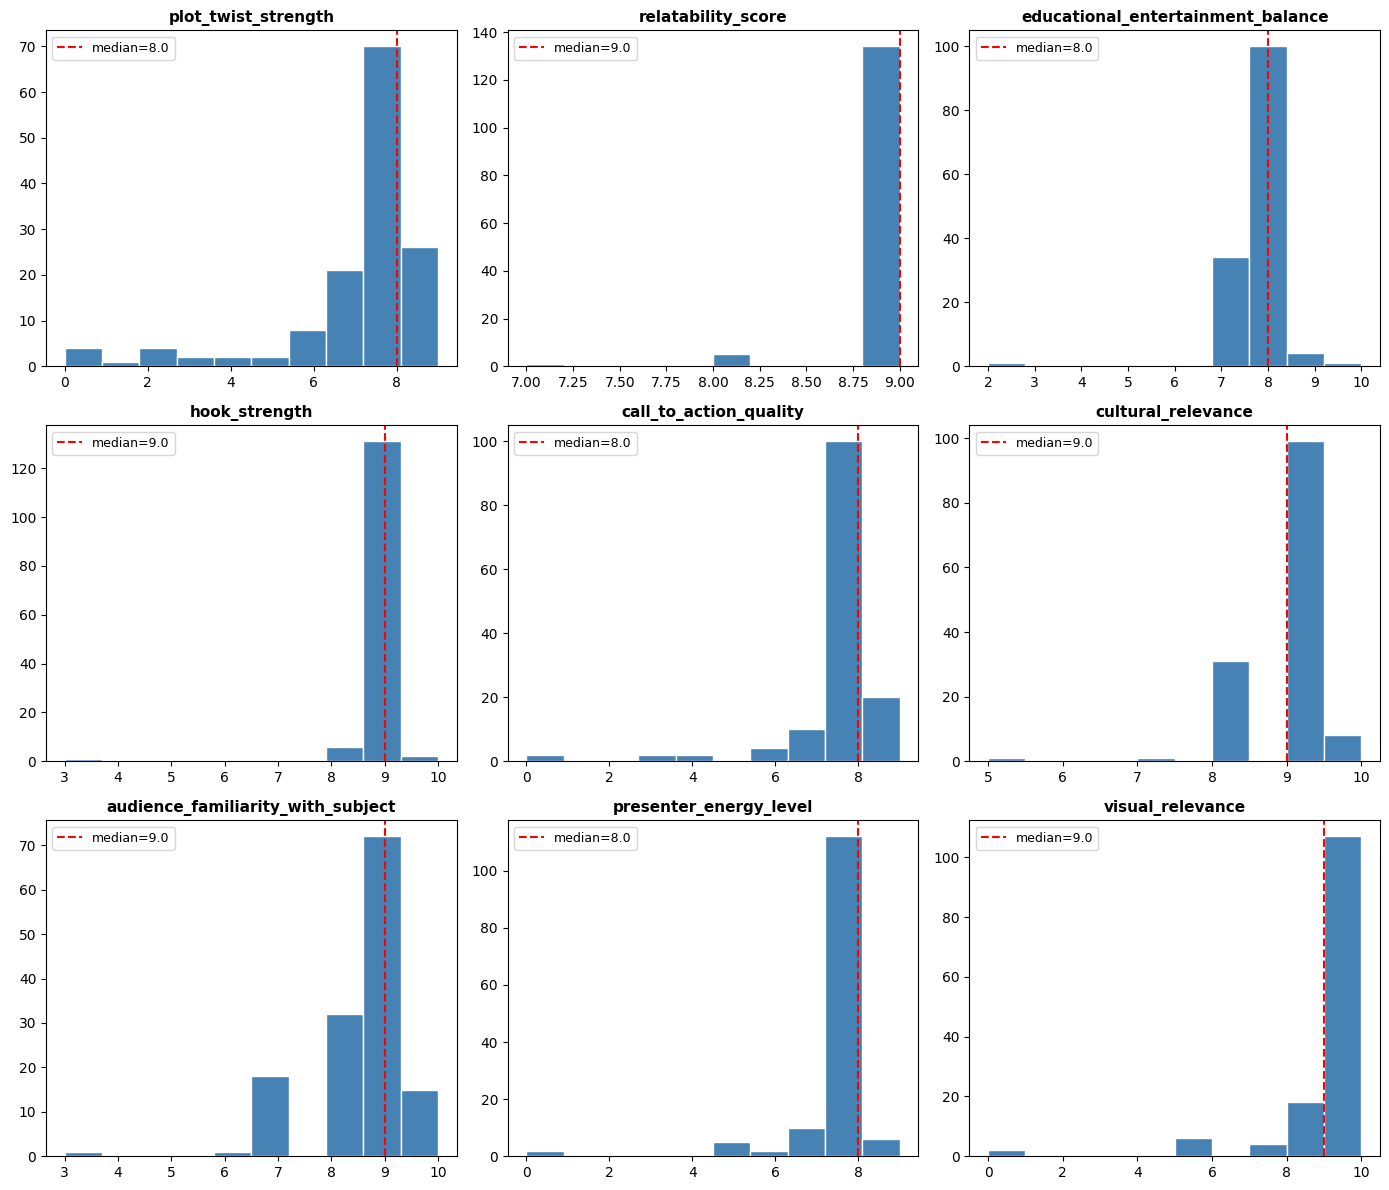


Numeric Feature Summary:
       plot_twist_strength  relatability_score  educational_entertainment_balance  hook_strength  call_to_action_quality  cultural_relevance  audience_familiarity_with_subject  presenter_energy_level  visual_relevance
count                140.0               140.0                              140.0          140.0                   140.0               140.0                              139.0                   137.0             137.0
mean                   7.3                 9.0                                7.8            8.9                     7.8                 8.8                                8.6                     7.7               8.5
std                    2.0                 0.2                                0.7            0.6                     1.3                 0.6                                1.0                     1.2               1.4
min                    0.0                 7.0                                2.0            3.0      

In [3]:
n_num = len(numeric_feats)
cols = 3
rows = (n_num + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes_flat = axes.flatten() if n_num > 1 else [axes]

for i, feat in enumerate(numeric_feats):
    ax = axes_flat[i]
    vals = pd.to_numeric(df[feat], errors='coerce').dropna()
    ax.hist(vals, bins=10, color='steelblue', edgecolor='white')
    ax.set_title(feat, fontsize=11, fontweight='bold')
    ax.axvline(vals.median(), color='red', linestyle='--', label=f'median={vals.median():.1f}')
    ax.legend(fontsize=9)

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.tight_layout()
plt.show()

print('\nNumeric Feature Summary:')
numeric_df = df[numeric_feats].apply(pd.to_numeric, errors='coerce')
print(numeric_df.describe().round(1).to_string())

## Correlation: Numeric Format Features vs Performance Metrics

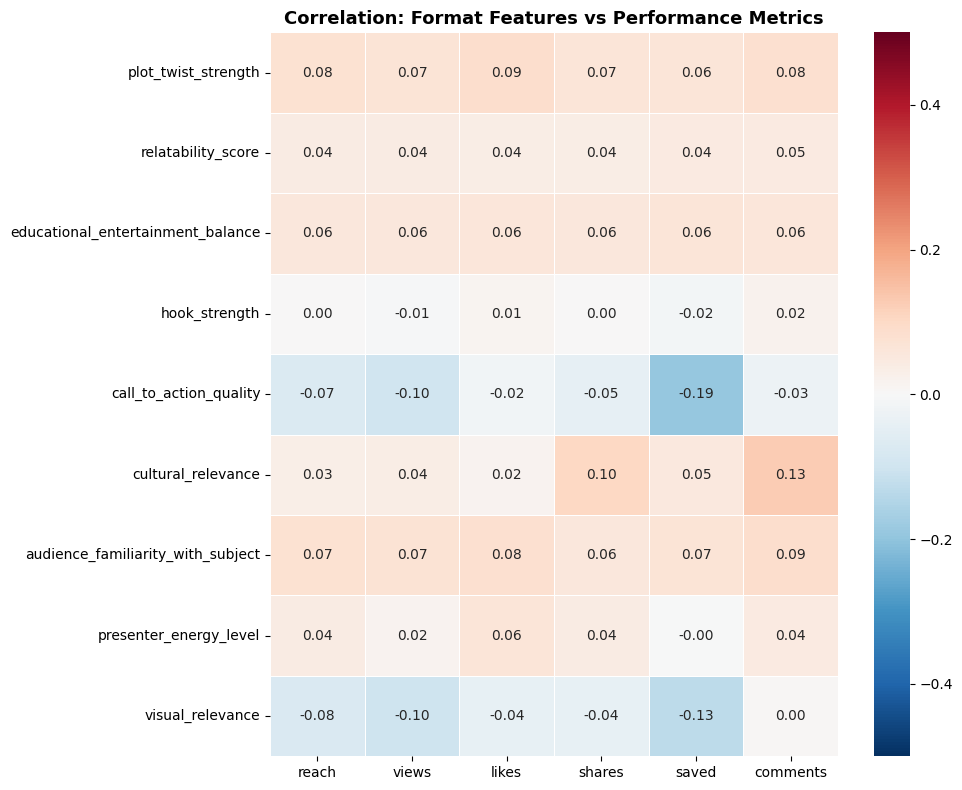


Top correlations with Reach:
  plot_twist_strength                      +0.077
  visual_relevance                         -0.076
  audience_familiarity_with_subject        +0.074
  call_to_action_quality                   -0.073
  educational_entertainment_balance        +0.059
  relatability_score                       +0.042
  presenter_energy_level                   +0.040
  cultural_relevance                       +0.035
  hook_strength                            +0.003


In [4]:
metrics = ['reach', 'views', 'likes', 'shares', 'saved', 'comments']
available_metrics = [m for m in metrics if m in df.columns]

corr_data = df[numeric_feats + available_metrics].apply(pd.to_numeric, errors='coerce')
corr_matrix = corr_data.corr().loc[numeric_feats, available_metrics]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-0.5, vmax=0.5, ax=ax, linewidths=0.5)
ax.set_title('Correlation: Format Features vs Performance Metrics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nTop correlations with Reach:')
if 'reach' in corr_matrix.columns:
    reach_corr = corr_matrix['reach'].sort_values(key=abs, ascending=False)
    for feat, val in reach_corr.items():
        direction = '+' if val > 0 else '-'
        print(f'  {feat:40s} {direction}{abs(val):.3f}')

## Categorical Features vs Reach (median comparison)


presenter_combination
                       Median Reach    Mean Reach  N Posts
presenter_combination                                     
presenter_b_presenter_c                   4523.0   4523.000000        1
presenter_c                        3164.0  28770.111111        9
presenter_b                         2678.0   6579.270270       37
guest                        2130.0   5184.270270       37
presenter_a                       1661.5   4014.696429       56



subject_type
                Median Reach    Mean Reach  N Posts
subject_type                                       
person                2347.0   2510.925926       27
strategy              2341.0   8013.552083       96
cultural_trend        2292.5  11146.333333        6
company               1935.0   1777.636364       11


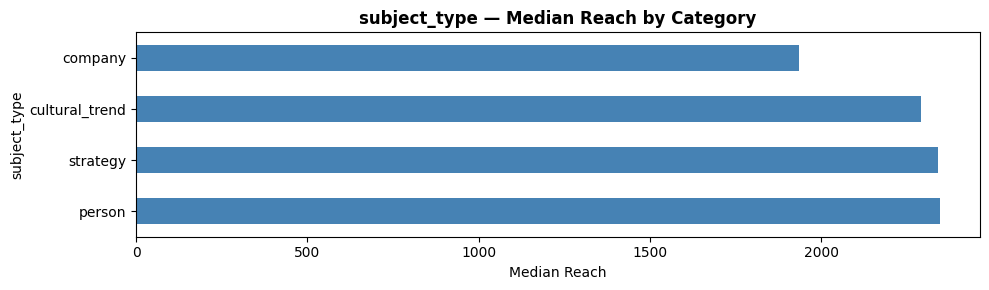


use_of_specific_numbers
                         Median Reach   Mean Reach  N Posts
use_of_specific_numbers                                    
True                           2335.0  6810.416667      120
False                          1592.5  5313.900000       20


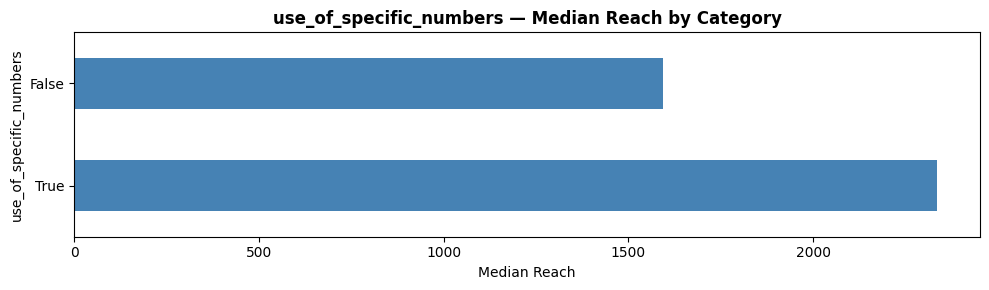


narrative_complexity
                      Median Reach   Mean Reach  N Posts
narrative_complexity                                    
single_arc                  2331.5  7147.572581      124
layered                     2142.0  2326.812500       16


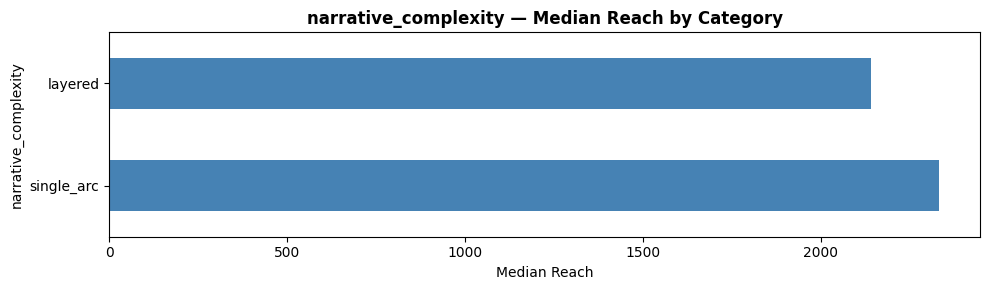


tone_of_voice
               Median Reach   Mean Reach  N Posts
tone_of_voice                                    
colloquial           2710.0  2437.000000        4
engaging             2335.0  6960.170543      129
provocative          1384.0  2274.000000        7


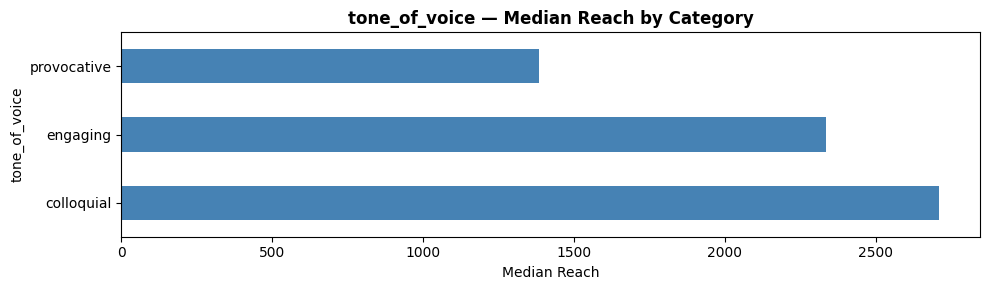


pop_culture_focus
                   Median Reach    Mean Reach  N Posts
pop_culture_focus                                     
pop_culture              4307.0  38801.000000        5
business                 2307.0   5403.874074      135


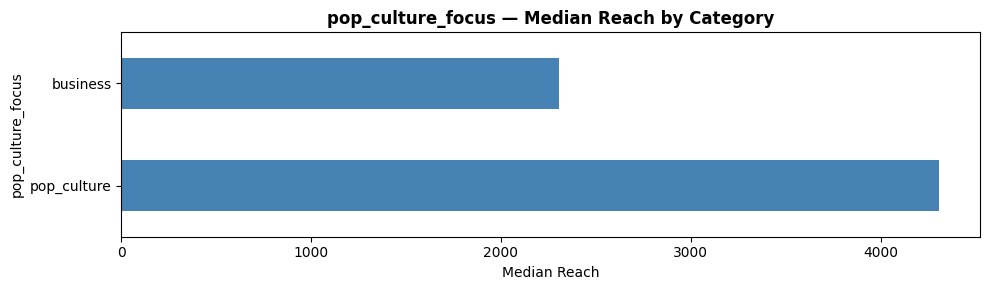

In [5]:
if 'reach' in df.columns:
    for feat in categorical_feats:
        grouped = df.groupby(feat)['reach'].agg(['median', 'mean', 'count']).sort_values('median', ascending=False)
        grouped.columns = ['Median Reach', 'Mean Reach', 'N Posts']
        print(f'\n{"="*60}')
        print(f'{feat}')
        print(f'{"="*60}')
        print(grouped.to_string())

        fig, ax = plt.subplots(figsize=(10, max(3, len(grouped) * 0.6)))
        grouped['Median Reach'].plot(kind='barh', ax=ax, color='steelblue')
        ax.set_title(f'{feat} — Median Reach by Category', fontweight='bold')
        ax.set_xlabel('Median Reach')
        plt.tight_layout()
        plt.show()